# 🌽 Corn (Maize) Leaf Disease Classification —  ML Pipeline

**Goal:** classify maize leaf photos into **Blight**, **Common_Rust**, **Gray_Leaf_Spot** and **Healthy** so smallholder
farmers can spot disease early, protect their yield and get a fair price for their harvest. This extends my
Introduction to ML summative (WFP Kenya food prices), where maize was the most-traded commodity.

This notebook covers the **offline** half of the pipeline:

| Step | Section |
|---|---|
| 1. Data acquisition | Upload the raw Kaggle zip → extract → detect class folders |
| 2. Data processing | Integrity check, RGB standardisation, MD5 de-duplication, stratified split |
| 3. Feature analysis | Class distribution, chlorophyll–necrosis colour index, lesion texture contrast |
| 4. Model creation | Custom CNN **trained from scratch**, with augmentation, regularisation and class weights |
| 5. Model testing | Accuracy, macro/weighted precision–recall–F1, confusion matrix, ROC-AUC |
| 6. Prediction | Single-image prediction function used later by the API |

Everything is saved to **Google Drive** (`MyDrive/corn_disease_mlops`) so the FastAPI backend, Streamlit UI, Docker
and Locust steps can reuse the exact same data and model.

> **Runtime:** use `Runtime → Change runtime type → T4 GPU`. Training a CNN from scratch takes about 10–20 minutes on a GPU, but hours on CPU.

## 0. Setup — mount Google Drive and create the project folders

In [ ]:
import os, sys, io, json, glob, time, shutil, random, hashlib, zipfile, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image, ImageOps, UnidentifiedImageError
import tensorflow as tf

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    BASE_DIR = Path('/content/drive/MyDrive/corn_disease_mlops')
    WORK_DIR = Path('/content')                      # fast local disk for extraction/training
except ImportError:                                  # running locally (Jupyter / VS Code)
    IN_COLAB = False
    BASE_DIR = Path(os.getenv('CORN_BASE_DIR', Path.cwd().parent)).resolve()
    WORK_DIR = Path(os.getenv('CORN_WORK_DIR', '/tmp/corn_work'))

DATA_DIR   = BASE_DIR / 'data'
TRAIN_DIR  = DATA_DIR / 'train'
TEST_DIR   = DATA_DIR / 'test'
DEMO_DIR   = BASE_DIR / 'demo_upload_batch'
MODELS_DIR = BASE_DIR / 'models'
SRC_DIR    = BASE_DIR / 'src'
for d in [TRAIN_DIR, TEST_DIR, DEMO_DIR, MODELS_DIR, SRC_DIR]:
    d.mkdir(parents=True, exist_ok=True)

RAW_EXTRACT_DIR = WORK_DIR / 'raw_extracted'
LOCAL_DATA_DIR  = WORK_DIR / 'local_data'           # local copy of train/test for fast tf.data reads
MODEL_PATH      = MODELS_DIR / 'corn_disease_model.keras'

CLASS_NAMES = ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']
IMG_SIZE    = 224
BATCH_SIZE  = 32

print('Running in Colab:', IN_COLAB)
print('BASE_DIR        :', BASE_DIR)
import keras
print('TensorFlow      :', tf.__version__, '| Keras:', keras.__version__)
print('GPU             :', tf.config.list_physical_devices('GPU') or 'none (CPU)')

Mounted at /content/drive
Running in Colab: True
BASE_DIR        : /content/drive/MyDrive/corn_disease_mlops
TensorFlow      : 2.21.0 | Keras: 3.13.2
GPU             : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Data acquisition — upload the raw Kaggle zip

Dataset: **Corn or Maize Leaf Disease Dataset**
How this cell behaves:
* If `data/train` in Drive **already has images** and `FORCE_UPLOAD = False`, the upload is skipped (re-runs are fast).
* Otherwise it looks for `raw_corn_data.zip` in your Drive project folder; if it's not there, it opens an **upload
  button** — choose your `raw_corn_data.zip`. A copy is kept in Drive so you never have to upload again.

In [ ]:
FORCE_UPLOAD = False          # True = wipe data/train, data/test, demo_upload_batch and rebuild from the zip
RAW_ZIP_NAME = 'raw_corn_data.zip'

def count_images(folder):
    exts = ('.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp', '.tif', '.tiff')
    return sum(1 for p in Path(folder).rglob('*') if p.suffix.lower() in exts)

existing = count_images(TRAIN_DIR)
NEED_PROCESSING = FORCE_UPLOAD or existing == 0
print(f'Images already in {TRAIN_DIR}: {existing}')

raw_zip_path = None
if NEED_PROCESSING:
    drive_zip = BASE_DIR / RAW_ZIP_NAME
    local_zip = os.getenv('CORN_RAW_ZIP')                    # local runs: export CORN_RAW_ZIP=/path/to.zip
    if drive_zip.exists():
        raw_zip_path = drive_zip
        print('Using zip already stored in Drive:', drive_zip)
    elif local_zip and Path(local_zip).exists():
        raw_zip_path = Path(local_zip)
    elif IN_COLAB:
        from google.colab import files
        print('Choose your raw Kaggle zip (e.g. raw_corn_data.zip)...')
        uploaded = files.upload()
        zip_names = [n for n in uploaded if n.lower().endswith('.zip')]
        if not zip_names:
            raise ValueError('Please upload a .zip file.')
        raw_zip_path = WORK_DIR / zip_names[0]
        with open(raw_zip_path, 'wb') as f:
            f.write(uploaded[zip_names[0]])
        shutil.copy(raw_zip_path, drive_zip)                  # persistent copy for future runs
        print('Saved a copy to Drive:', drive_zip)
    else:
        raise FileNotFoundError('No raw zip found. Set CORN_RAW_ZIP or place raw_corn_data.zip in BASE_DIR.')

    if RAW_EXTRACT_DIR.exists():
        shutil.rmtree(RAW_EXTRACT_DIR)
    RAW_EXTRACT_DIR.mkdir(parents=True)
    with zipfile.ZipFile(raw_zip_path) as zf:
        zf.extractall(RAW_EXTRACT_DIR)
    print(f'Extracted {count_images(RAW_EXTRACT_DIR)} image files to {RAW_EXTRACT_DIR}')
else:
    print('Skipping upload — using the cleaned split already in Drive. Set FORCE_UPLOAD = True to rebuild.')

Images already in /content/drive/MyDrive/corn_disease_mlops/data/train: 3348
Skipping upload — using the cleaned split already in Drive. Set FORCE_UPLOAD = True to rebuild.


## 2. Data processing — clean, de-duplicate and split

1. **Auto-detect class folders** anywhere inside the zip (handles `data/Blight`, `Corn/Common Rust`, `Gray_Leaf_Spot` …).
   If the zip contains several copies of a class folder (e.g. `train/Blight` and `val/Blight`) they are merged.
2. **Integrity check:** every file is fully decoded with Pillow; corrupt/truncated/tiny files are removed.
3. **Standardise:** EXIF rotation fixed, converted to **3-channel RGB**, saved as **JPEG**.
4. **De-duplicate:** exact duplicates (same MD5 of the original bytes) are removed. If the same image appears under
   **two different classes**, all copies are dropped because the label is ambiguous.
5. **Stratified split per class:** **5 images → `demo_upload_batch/`** (kept unseen for the UI retraining demo),
   **80 % → `train/`**, the rest (**≈18–20 %**) → `test/`.

In [ ]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp', '.tif', '.tiff'}
CLASS_ALIASES = {
    'blight': 'Blight', 'northern_leaf_blight': 'Blight', 'leaf_blight': 'Blight',
    'common_rust': 'Common_Rust', 'rust': 'Common_Rust',
    'gray_leaf_spot': 'Gray_Leaf_Spot', 'grey_leaf_spot': 'Gray_Leaf_Spot',
    'cercospora_leaf_spot_gray_leaf_spot': 'Gray_Leaf_Spot',
    'healthy': 'Healthy',
}

def normalize_class_name(name):
    import re
    key = re.sub(r'[^a-z]+', '_', name.lower()).strip('_')
    key = re.sub(r'^corn_maize_+', '', key)
    key = re.sub(r'^(corn|maize)_+', '', key)
    return CLASS_ALIASES.get(key)

def detect_class_folders(root):
    # Return {class_name: [folders]} for every folder whose name maps to a class
    found = {c: [] for c in CLASS_NAMES}
    for d in sorted(Path(root).rglob('*')):
        if d.is_dir() and '__MACOSX' not in d.parts:
            cls = normalize_class_name(d.name)
            if cls:
                found[cls].append(d)
    # drop folders nested inside another folder of the same class
    for cls, dirs in found.items():
        found[cls] = [d for d in dirs if not any(o != d and o in d.parents for o in dirs)]
    return found

def standardize_image_bytes(data):
    with Image.open(io.BytesIO(data)) as probe:
        probe.verify()
    img = Image.open(io.BytesIO(data)); img.load()
    img = ImageOps.exif_transpose(img)
    if img.mode != 'RGB':
        img = img.convert('RGB')
    if min(img.size) < 32:
        raise ValueError('too small')
    return img

if NEED_PROCESSING:
    class_dirs = detect_class_folders(RAW_EXTRACT_DIR)
    missing = [c for c, d in class_dirs.items() if not d]
    if missing:
        raise ValueError(f'Could not find folders for {missing}. Found: { {c: [str(x) for x in d] for c, d in class_dirs.items()} }')
    for c, dirs in class_dirs.items():
        print(f'{c:15s} <- ' + ', '.join(str(d.relative_to(RAW_EXTRACT_DIR)) for d in dirs))

    # ---- pass 1: hash + integrity check -------------------------------------------------
    summary = {c: {'original': 0, 'corrupt': 0, 'duplicates': 0, 'label_conflicts': 0} for c in CLASS_NAMES}
    records = []                                              # (class, path, md5)
    for cls, dirs in class_dirs.items():
        seen = set()
        for d in dirs:
            for f in sorted(d.rglob('*')):
                if not f.is_file() or f.suffix.lower() not in IMAGE_EXTS or f.name.startswith('.'):
                    continue
                summary[cls]['original'] += 1
                data = f.read_bytes()
                digest = hashlib.md5(data).hexdigest()
                if digest in seen:
                    summary[cls]['duplicates'] += 1
                    continue
                try:
                    standardize_image_bytes(data)
                except Exception:
                    summary[cls]['corrupt'] += 1
                    continue
                seen.add(digest)
                records.append((cls, f, digest))

    # ---- images that appear in more than one class -> ambiguous label, drop them ---------
    df_rec = pd.DataFrame(records, columns=['cls', 'path', 'md5'])
    conflict_md5 = set(df_rec.groupby('md5')['cls'].nunique().loc[lambda s: s > 1].index)
    for cls in CLASS_NAMES:
        summary[cls]['label_conflicts'] = int(((df_rec.cls == cls) & df_rec.md5.isin(conflict_md5)).sum())
    df_rec = df_rec[~df_rec.md5.isin(conflict_md5)].reset_index(drop=True)

    # ---- pass 2: stratified split + save as RGB JPEG -------------------------------------
    for d in [TRAIN_DIR, TEST_DIR, DEMO_DIR, LOCAL_DATA_DIR]:
        if d.exists():
            shutil.rmtree(d)
    rng = np.random.default_rng(SEED)
    N_DEMO, TRAIN_FRAC = 5, 0.80
    for cls in CLASS_NAMES:
        rows = df_rec[df_rec.cls == cls].sample(frac=1, random_state=SEED).reset_index(drop=True)
        n = len(rows)
        n_train = min(int(round(n * TRAIN_FRAC)), max(n - N_DEMO - 1, 0))   # always leave >= 1 test image
        splits = {'demo': rows.iloc[:N_DEMO],
                  'train': rows.iloc[N_DEMO:N_DEMO + n_train],
                  'test': rows.iloc[N_DEMO + n_train:]}
        for split, part in splits.items():
            dest_root = {'demo': WORK_DIR / 'clean' / 'demo_upload_batch',
                         'train': LOCAL_DATA_DIR / 'train', 'test': LOCAL_DATA_DIR / 'test'}[split]
            out_dir = dest_root / cls
            out_dir.mkdir(parents=True, exist_ok=True)
            for i, r in enumerate(part.itertuples()):
                img = standardize_image_bytes(Path(r.path).read_bytes())
                img.save(out_dir / f'{cls.lower()}_{r.md5[:10]}.jpg', 'JPEG', quality=95)
            summary[cls][split] = len(part)

    # ---- persist to Drive -----------------------------------------------------------------
    print('Copying cleaned data to Google Drive (a few minutes for ~4,000 images)...')
    shutil.copytree(LOCAL_DATA_DIR / 'train', TRAIN_DIR, dirs_exist_ok=True)
    shutil.copytree(LOCAL_DATA_DIR / 'test', TEST_DIR, dirs_exist_ok=True)
    shutil.copytree(WORK_DIR / 'clean' / 'demo_upload_batch', DEMO_DIR, dirs_exist_ok=True)

    summary_df = pd.DataFrame(summary).T[['original', 'corrupt', 'duplicates', 'label_conflicts', 'train', 'test', 'demo']]
    summary_df.loc['TOTAL'] = summary_df.sum()
    summary_df['test_%'] = (100 * summary_df['test'] / (summary_df['train'] + summary_df['test'] + summary_df['demo'])).round(1)
    summary_df.to_csv(MODELS_DIR / 'data_cleaning_summary.csv')
    display(summary_df)
else:
    # Re-run: copy the Drive split to local disk so training doesn't read thousands of files over Drive
    if not (LOCAL_DATA_DIR / 'train').exists():
        print('Copying train/test from Drive to local disk...')
        shutil.copytree(TRAIN_DIR, LOCAL_DATA_DIR / 'train', dirs_exist_ok=True)
        shutil.copytree(TEST_DIR, LOCAL_DATA_DIR / 'test', dirs_exist_ok=True)
    summary_csv = MODELS_DIR / 'data_cleaning_summary.csv'
    if summary_csv.exists():
        display(pd.read_csv(summary_csv, index_col=0))
    counts = {s: {c: count_images(LOCAL_DATA_DIR / s / c) for c in CLASS_NAMES} for s in ['train', 'test']}
    counts['demo'] = {c: count_images(DEMO_DIR / c) for c in CLASS_NAMES}
    display(pd.DataFrame(counts))

LOCAL_TRAIN, LOCAL_TEST = LOCAL_DATA_DIR / 'train', LOCAL_DATA_DIR / 'test'

Copying train/test from Drive to local disk...


,train,test,demo
Blight,915,224,5
Common_Rust,1045,256,5
Gray_Leaf_Spot,458,109,5
Healthy,930,227,5


### Preprocessing used by the model

These functions are an **exact copy of `src/preprocessing.py`**, so the deployed API prepares images the same way:

* decode → RGB → resize to **224×224** (bilinear) → scale to **[-1, 1]** (`x / 127.5 − 1`, centred on zero, which helps training converge)
* **Augmentation (training only, inside `tf.data`)**: horizontal/vertical flips, 90° rotations, brightness,
  contrast and saturation jitter. Leaves have no "up", and photos are taken in very different light in the field.
* A stratified **10 % of `train/`** is held out as a validation set for early stopping; `test/` is never touched
  during training.

train: 3013 | validation: 335 | test: 816


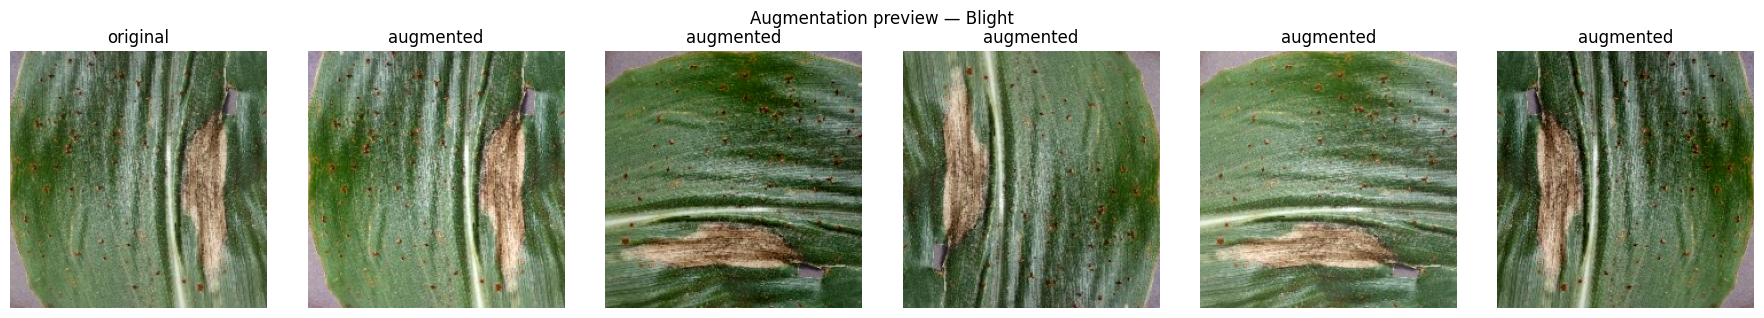

In [ ]:
from sklearn.model_selection import train_test_split
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_pixels(image):
    image = tf.image.resize(tf.cast(image, tf.float32), (IMG_SIZE, IMG_SIZE), method='bilinear')
    return image / 127.5 - 1.0

def list_image_files(directory, class_names=CLASS_NAMES):
    paths, labels = [], []
    for idx, cls in enumerate(class_names):
        for f in sorted((Path(directory) / cls).glob('*')):
            if f.suffix.lower() in IMAGE_EXTS:
                paths.append(str(f)); labels.append(idx)
    return paths, labels

def _load_from_path(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    return tf.image.resize(tf.cast(img, tf.float32), (IMG_SIZE, IMG_SIZE), method='bilinear'), label

def _augment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    img = tf.image.random_brightness(img, max_delta=25.0)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    img = tf.image.random_saturation(img, 0.85, 1.15)
    return tf.clip_by_value(img, 0.0, 255.0), label

def _scale(img, label):
    return img / 127.5 - 1.0, label

def build_dataset(paths, labels, training, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(_load_from_path, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(_augment, num_parallel_calls=AUTOTUNE)
    return ds.map(_scale, num_parallel_calls=AUTOTUNE).batch(batch_size).prefetch(AUTOTUNE)

all_train_paths, all_train_labels = list_image_files(LOCAL_TRAIN)
test_paths, test_labels = list_image_files(LOCAL_TEST)
tr_paths, val_paths, tr_labels, val_labels = train_test_split(
    all_train_paths, all_train_labels, test_size=0.10, stratify=all_train_labels, random_state=SEED)

train_ds = build_dataset(tr_paths, tr_labels, training=True)
val_ds   = build_dataset(val_paths, val_labels, training=False)
test_ds  = build_dataset(test_paths, test_labels, training=False)
print(f'train: {len(tr_paths)} | validation: {len(val_paths)} | test: {len(test_paths)}')

# Show the same leaf with 5 random augmentations
sample_img, _ = _load_from_path(tf.constant(tr_paths[0]), 0)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
axes[0].imshow(sample_img.numpy().astype('uint8')); axes[0].set_title('original')
for ax in axes[1:]:
    aug, _ = _augment(sample_img, 0)
    ax.imshow(aug.numpy().astype('uint8')); ax.set_title('augmented')
for ax in axes: ax.axis('off')
plt.suptitle(f'Augmentation preview — {CLASS_NAMES[tr_labels[0]]}'); plt.tight_layout(); plt.show()

## 3. Feature extraction & EDA

Images have no columns, so three **image-level features** are extracted from every training image:

1. **Class sample distribution** — how many images each class has (drives class weights and metric choice).
2. **Chlorophyll vs. necrosis colour index** = `mean(Green) − mean(Red)` over the 224×224 image.
   Healthy tissue is green (high index); dead, rusty or blighted tissue turns red-brown/tan (index falls).
3. **Lesion texture contrast** = variance of the **Laplacian** of the grayscale image. The Laplacian responds to
   sharp intensity changes, so many small spots/pustules give a high value and smooth leaves a low one.

In [ ]:
def extract_features(path):
    img = cv2.imread(path)                                         # BGR uint8
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    b, g, r = [img[..., i].astype(np.float32) for i in range(3)]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return {
        'mean_red': float(r.mean()), 'mean_green': float(g.mean()), 'mean_blue': float(b.mean()),
        'color_index': float(g.mean() - r.mean()),
        'texture_contrast': float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        'brightness': float(gray.mean()),
    }

t0 = time.time()
feat_rows = []
for p, y in zip(all_train_paths, all_train_labels):
    row = extract_features(p); row['class'] = CLASS_NAMES[y]; feat_rows.append(row)
feat_df = pd.DataFrame(feat_rows)
feat_df['class'] = pd.Categorical(feat_df['class'], CLASS_NAMES, ordered=True)
print(f'Extracted features for {len(feat_df)} images in {time.time() - t0:.1f}s')
display(feat_df.groupby('class', observed=False)[['color_index', 'texture_contrast', 'mean_red', 'mean_green', 'brightness']]
        .agg(['mean', 'median', 'std']).round(2))

Extracted features for 3348 images in 12.5s


color_index               texture_contrast                  \
                      mean median    std             mean  median     std   
class                                                                       
Blight                8.10   8.43  10.22           718.95  628.32  454.98   
Common_Rust           8.17   8.16   8.86          1027.65  974.80  377.32   
Gray_Leaf_Spot        7.09   5.90   8.65          1044.80  884.61  610.11   
Healthy              34.80  33.33   9.09           464.05  265.95  513.05   

               mean_red                mean_green                brightness  \
                   mean  median    std       mean  median    std       mean   
class                                                                         
Blight           114.73  115.16  13.62     122.84  123.09  11.88     117.58   
Common_Rust       91.47   91.31  18.72      99.64   99.27  19.66      93.90   
Gray_Leaf_Spot   117.66  117.33  14.55     124.75  124.06  13.42     119.46   
Healthy          128.93  130.28  28.99     163.73  166.75  24.90     148.52   

                               
                median    std  
class                          
Blight          118.06  11.51  
Common_Rust      93.59  18.49  
Gray_Leaf_Spot  119.34  12.83  
Healthy         151.42  26.16

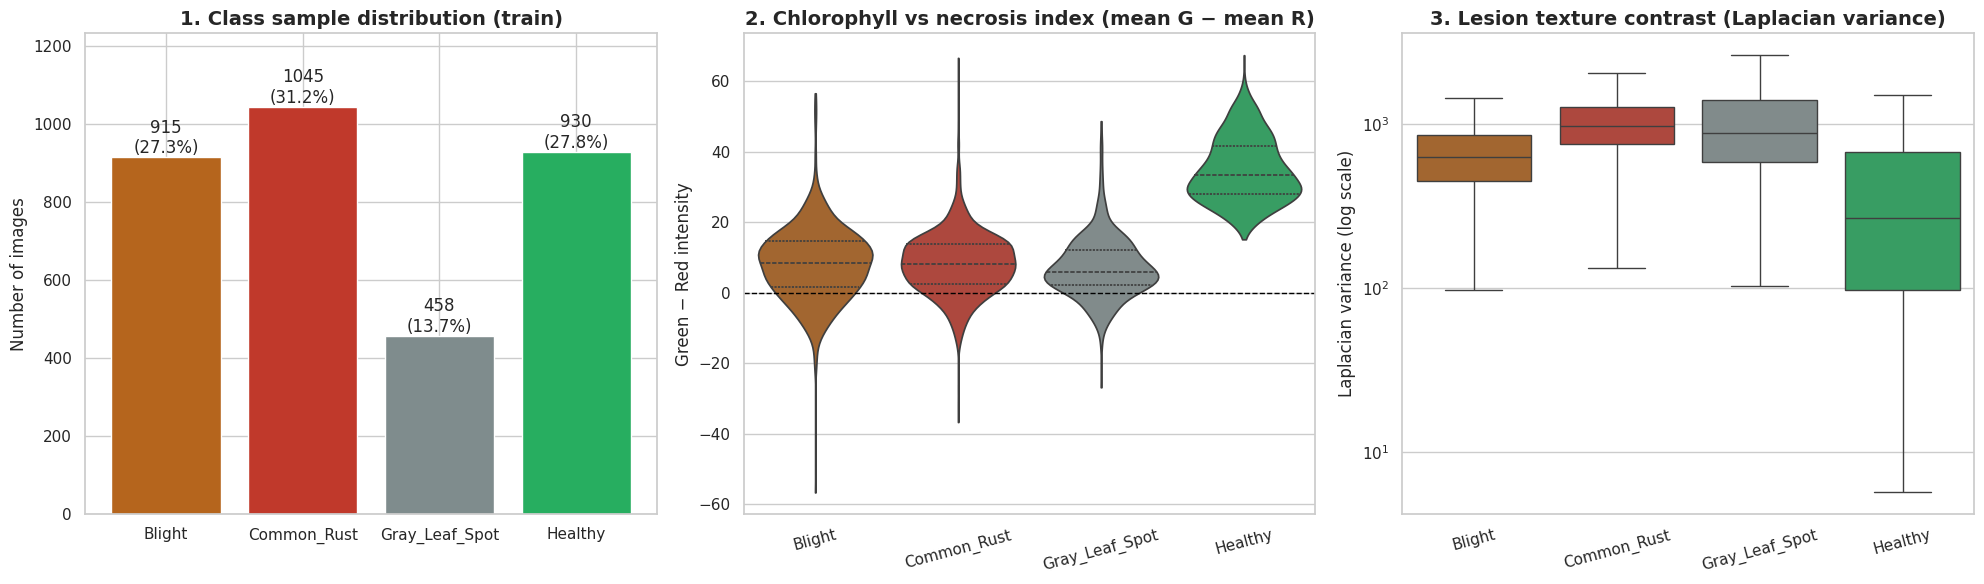

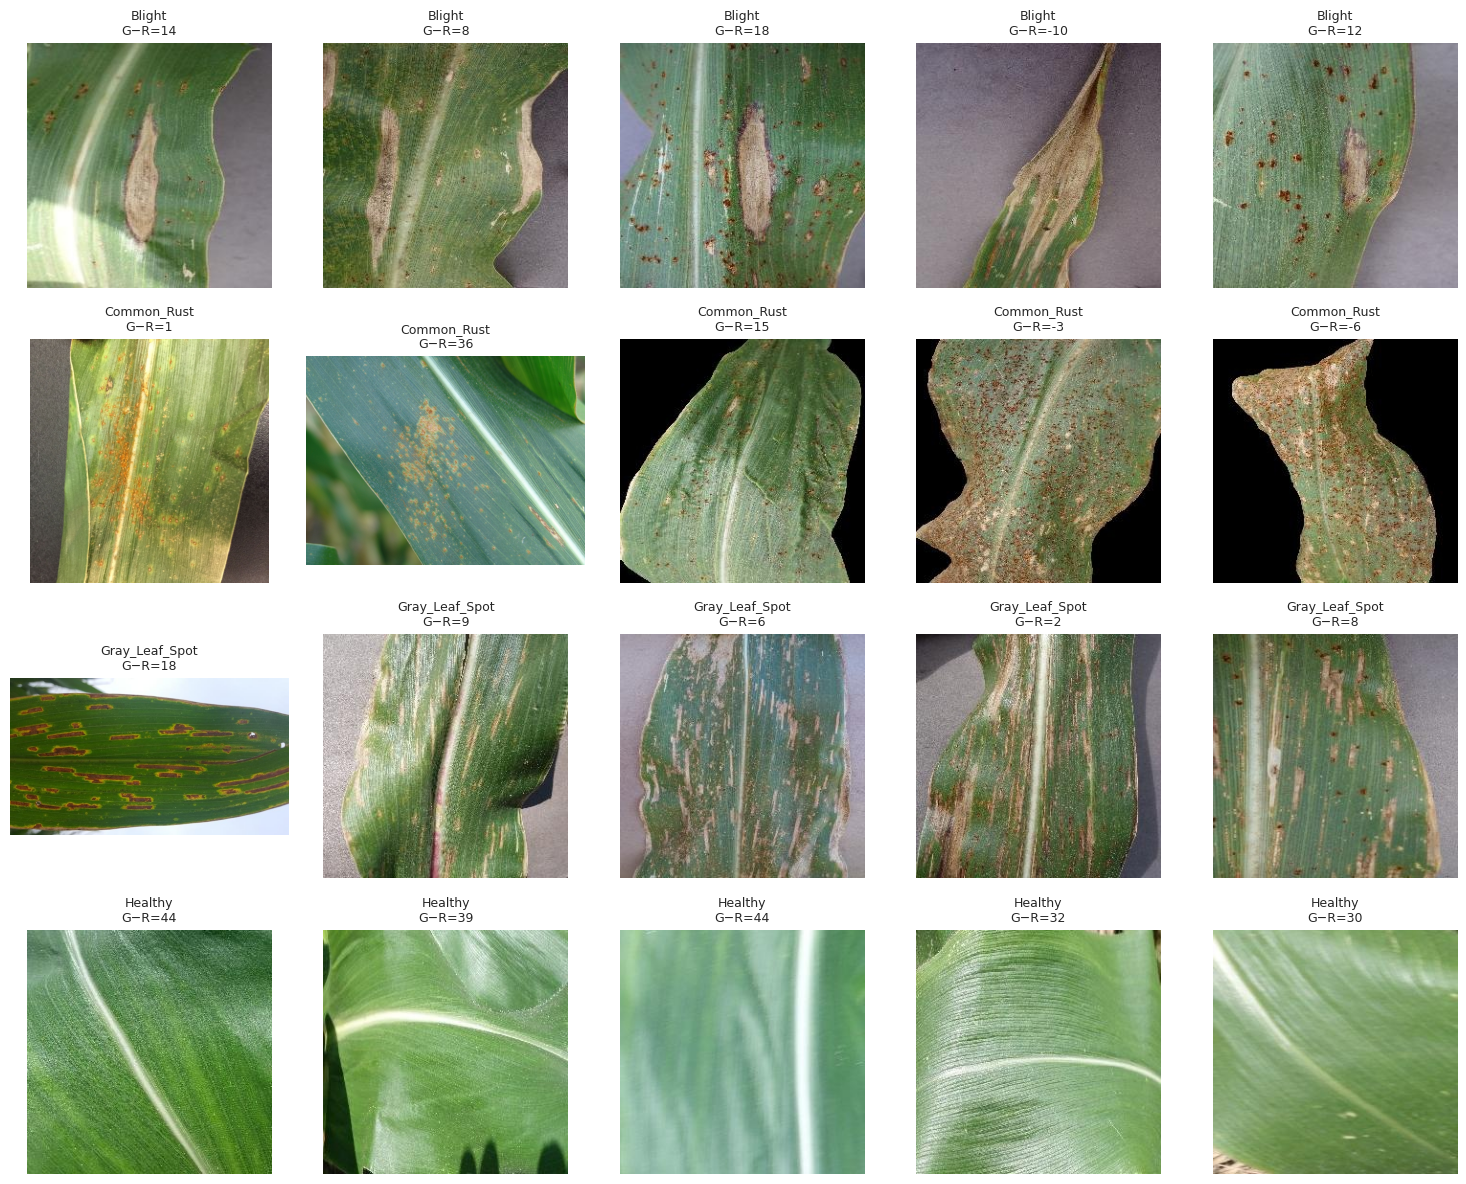

In [ ]:
palette = {'Blight': '#B5651D', 'Common_Rust': '#C0392B', 'Gray_Leaf_Spot': '#7F8C8D', 'Healthy': '#27AE60'}
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1) class distribution
counts = feat_df['class'].value_counts().reindex(CLASS_NAMES)
bars = axes[0].bar(CLASS_NAMES, counts.values, color=[palette[c] for c in CLASS_NAMES])
for bar, v in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v, f'{v}\n({100 * v / counts.sum():.1f}%)', ha='center', va='bottom')
axes[0].set_title('1. Class sample distribution (train)', fontsize=14, weight='bold')
axes[0].set_ylabel('Number of images'); axes[0].set_ylim(0, counts.max() * 1.18)

# 2) colour index
sns.violinplot(data=feat_df, x='class', y='color_index', hue='class', palette=palette, legend=False, ax=axes[1], cut=0, inner='quartile')
axes[1].axhline(0, color='black', lw=1, ls='--')
axes[1].set_title('2. Chlorophyll vs necrosis index (mean G − mean R)', fontsize=14, weight='bold')
axes[1].set_xlabel(''); axes[1].set_ylabel('Green − Red intensity')

# 3) texture contrast (log scale: heavy right tail)
sns.boxplot(data=feat_df, x='class', y='texture_contrast', hue='class', palette=palette, legend=False, ax=axes[2], showfliers=False)
axes[2].set_yscale('log')
axes[2].set_title('3. Lesion texture contrast (Laplacian variance)', fontsize=14, weight='bold')
axes[2].set_xlabel(''); axes[2].set_ylabel('Laplacian variance (log scale)')

for ax in axes[1:]: ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig(MODELS_DIR / 'eda_features.png', dpi=200, bbox_inches='tight')
plt.show()

# Sample images per class
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(15, 12))
for i, cls in enumerate(CLASS_NAMES):
    picks = feat_df[feat_df['class'] == cls].sample(5, random_state=SEED).index
    for j, k in enumerate(picks):
        axes[i, j].imshow(Image.open(all_train_paths[k])); axes[i, j].axis('off')
        axes[i, j].set_title(f"{cls}\nG−R={feat_df.loc[k, 'color_index']:.0f}", fontsize=9)
plt.tight_layout(); plt.savefig(MODELS_DIR / 'sample_images.png', dpi=120, bbox_inches='tight'); plt.show()

In [ ]:
# Export summary statistics (+ histograms so the Streamlit UI can redraw the plots without the images)
def class_stats(col):
    out = {}
    for cls in CLASS_NAMES:
        v = feat_df.loc[feat_df['class'] == cls, col]
        out[cls] = {'count': int(v.count()), 'mean': round(float(v.mean()), 3), 'median': round(float(v.median()), 3),
                    'std': round(float(v.std()), 3), 'min': round(float(v.min()), 3), 'max': round(float(v.max()), 3),
                    'q1': round(float(v.quantile(.25)), 3), 'q3': round(float(v.quantile(.75)), 3)}
    return out

def class_histograms(col, bins=30, log=False):
    vals = np.log10(feat_df[col].clip(lower=1e-6)) if log else feat_df[col]
    edges = np.histogram_bin_edges(vals, bins=bins)
    hist = {cls: np.histogram(vals[feat_df['class'] == cls], bins=edges)[0].tolist() for cls in CLASS_NAMES}
    return {'bin_edges': [round(float(e), 4) for e in edges], 'log10': log, 'counts': hist}

ci = class_stats('color_index'); tc = class_stats('texture_contrast')
dist = {c: int(n) for c, n in feat_df['class'].value_counts().reindex(CLASS_NAMES).items()}
total = sum(dist.values())
rank_ci = sorted(CLASS_NAMES, key=lambda c: ci[c]['median'], reverse=True)
rank_tc = sorted(CLASS_NAMES, key=lambda c: tc[c]['median'], reverse=True)
smallest, largest = min(dist, key=dist.get), max(dist, key=dist.get)

interpretations = {
    'class_distribution': (
        f"{largest} is the largest class ({dist[largest]} images, {100*dist[largest]/total:.1f}%) and {smallest} the smallest "
        f"({dist[smallest]}, {100*dist[smallest]/total:.1f}%), an imbalance ratio of {dist[largest]/dist[smallest]:.2f}:1. "
        f"Without correction the model would under-predict {smallest}, so training uses balanced class weights and we report "
        f"macro-averaged precision/recall/F1 (every class counts equally) instead of relying on accuracy alone."),
    'color_index': (
        f"Median Green−Red index from greenest to least green: " + ', '.join(f"{c} ({ci[c]['median']:.1f})" for c in rank_ci) + ". "
        f"{rank_ci[0]} leaves keep the most chlorophyll; {rank_ci[-1]} shows the strongest shift towards red/brown, consistent with "
        f"necrotic (dead) tissue and rust-coloured pustules. Colour alone separates healthy from diseased leaves fairly well, but the "
        f"overlapping distributions of the diseased classes show why the model also needs shape and texture."),
    'texture_contrast': (
        f"Median Laplacian variance from most to least textured: " + ', '.join(f"{c} ({tc[c]['median']:.0f})" for c in rank_tc) + ". "
        f"High values mean many sharp edges, e.g. scattered pustules or small lesions; low values mean smoother surfaces or large uniform "
        f"lesions. The wide, overlapping ranges also reflect differences in photo focus and background, which is why augmentation and a "
        f"CNN that learns its own features are used rather than hand-made thresholds."),
}

eda_stats = {
    'generated_at': datetime.now(timezone.utc).isoformat(),
    'n_train_images': total,
    'class_names': CLASS_NAMES,
    'class_distribution': dist,
    'class_distribution_pct': {c: round(100 * n / total, 2) for c, n in dist.items()},
    'imbalance_ratio': round(dist[largest] / dist[smallest], 3),
    'features': {
        'color_index': {'description': 'mean(Green) - mean(Red) pixel intensity (chlorophyll vs necrosis)',
                        'per_class': ci, 'histogram': class_histograms('color_index')},
        'texture_contrast': {'description': 'variance of the Laplacian of the grayscale image (lesion texture)',
                             'per_class': tc, 'histogram': class_histograms('texture_contrast', log=True)},
        'mean_rgb': {cls: {k: round(float(feat_df.loc[feat_df['class'] == cls, f'mean_{k}'].mean()), 2)
                           for k in ['red', 'green', 'blue']} for cls in CLASS_NAMES},
        'brightness': class_stats('brightness'),
    },
    'interpretations': interpretations,
}
with open(MODELS_DIR / 'eda_stats.json', 'w') as f:
    json.dump(eda_stats, f, indent=2)
print('Saved', MODELS_DIR / 'eda_stats.json', '\n')
for k, v in interpretations.items():
    print(f'■ {k}:\n  {v}\n')

Saved /content/drive/MyDrive/corn_disease_mlops/models/eda_stats.json 

■ class_distribution:
  Common_Rust is the largest class (1045 images, 31.2%) and Gray_Leaf_Spot the smallest (458, 13.7%), an imbalance ratio of 2.28:1. Without correction the model would under-predict Gray_Leaf_Spot, so training uses balanced class weights and we report macro-averaged precision/recall/F1 (every class counts equally) instead of relying on accuracy alone.

■ color_index:
  Median Green−Red index from greenest to least green: Healthy (33.3), Blight (8.4), Common_Rust (8.2), Gray_Leaf_Spot (5.9). Healthy leaves keep the most chlorophyll; Gray_Leaf_Spot shows the strongest shift towards red/brown, consistent with necrotic (dead) tissue and rust-coloured pustules. Colour alone separates healthy from diseased leaves fairly well, but the overlapping distributions of the diseased classes show why the model also needs shape and texture.

■ texture_contrast:
  Median Laplacian variance from most to least te

### What story do the three features tell?


**1. Class distribution — the data is imbalanced.** `Gray_Leaf_Spot` has roughly half as many images as the other
classes. A model that ignores this would learn to rarely predict Gray Leaf Spot, which is the worst outcome for a farmer
because that disease spreads in humid seasons and can strip a field. **Action:** balanced `class_weight` during
training, and macro-averaged metrics in evaluation.

**2. Chlorophyll vs. necrosis index — colour is a strong, biologically meaningful signal.** Healthy leaves have the
highest Green−Red index. Disease destroys chlorophyll: **Common Rust** adds reddish-brown pustules (more red) and
**Northern Leaf Blight** creates long tan, dead lesions, so their index drops. **Gray Leaf Spot** lesions are grey/tan
and narrow, so its index sits between them. Overlap between the three diseases means colour alone isn't enough.

**3. Lesion texture contrast — disease changes the leaf surface.** Rust's many small raised pustules create lots of
sharp edges (high Laplacian variance). Blight's large, uniform lesions and healthy leaves' smooth surface create fewer.
The long tails also reveal **photo-quality differences** (focus, background), a reminder that field photos taken by
farmers will vary, which is why the model uses augmentation and a CNN that learns its own features instead of fixed thresholds.

**Overall story:** disease shows up as *loss of green* and *added surface texture*. These are exactly the cues a CNN
can learn, but the classes overlap on any single feature, so a learned model combining colour, texture and shape is
needed, and class imbalance must be handled explicitly.

## 4. Model creation — custom CNN trained from scratch


**Architecture** (about 1.2 M parameters, ~5 MB):

| Stage | Layers | Output size |
|---|---|---|
| Input | 224×224 RGB, scaled to [-1, 1] | 224×224×3 |
| Stem | Conv 32 (3×3, stride 2) → BatchNorm → ReLU | 112×112×32 |
| Block 1 | 2 × [Conv 32 → BatchNorm → ReLU] → MaxPool → Dropout 0.15 | 56×56×32 |
| Block 2 | 2 × [Conv 64 → BatchNorm → ReLU] → MaxPool → Dropout 0.20 | 28×28×64 |
| Block 3 | 2 × [Conv 128 → BatchNorm → ReLU] → MaxPool → Dropout 0.25 | 14×14×128 |
| Block 4 | 2 × [Conv 256 → BatchNorm → ReLU] → MaxPool → Dropout 0.30 | 7×7×256 |
| Head | GlobalAveragePooling → Dropout 0.4 → Dense 128 ReLU → Dropout 0.3 → Dense 4 softmax | 4 |

**Why this design**
* **Stacked 3×3 convolutions** learn simple patterns first (edges, colour changes) and combine them in deeper blocks
  into lesion shapes: rust pustules, long blight lesions, rectangular gray spots.
* **Doubling filters while halving the image size** lets deeper layers describe larger regions of the leaf with
  richer features.
* **GlobalAveragePooling** instead of flattening keeps the head small (fewer parameters means less overfitting).
  Its 256 outputs (layer `gap`) are also used by the API's "is this a maize leaf?" check.

**Optimisation techniques** (important when training from scratch on ~3,300 images)
* **Regularisation:** L2 weight decay (1e-4) on every Conv/Dense layer, Dropout increasing with depth, and data
  augmentation (flips, rotations, brightness, contrast, saturation).
* **BatchNormalization** after every convolution: stabilises and speeds up training from random weights. Its
  momentum is set to **0.9** (default 0.99), so the averages it uses at prediction time keep up with the fast-changing
  weights. With the default, validation accuracy stayed at chance level while training accuracy was 99%.
* **Optimizer:** Adam (learning rate 1e-3), plus **ReduceLROnPlateau**, which halves the learning rate when validation
  loss stops improving for 3 epochs.
* **EarlyStopping** (patience 8, restores the best weights) and **ModelCheckpoint** (best `val_loss`, saved straight
  to Drive as `.keras`).
* **Class imbalance:** balanced `class_weight`, so Gray Leaf Spot (the smallest class) is not ignored.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# BatchNorm momentum 0.9 (Keras default 0.99): when training from scratch the weights change fast, and with
# 0.99 the running averages used at prediction time lag behind (training accuracy 99%, validation ~27%).
BN_MOMENTUM = 0.9

def conv_block(x, filters, name, l2=1e-4, dropout=0.15):
    reg = tf.keras.regularizers.l2(l2)
    for i in (1, 2):
        x = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False, kernel_regularizer=reg, name=f'{name}_conv{i}')(x)
        x = tf.keras.layers.BatchNormalization(momentum=BN_MOMENTUM, name=f'{name}_bn{i}')(x)
        x = tf.keras.layers.Activation('relu', name=f'{name}_relu{i}')(x)
    x = tf.keras.layers.MaxPooling2D(2, name=f'{name}_pool')(x)
    return tf.keras.layers.Dropout(dropout, name=f'{name}_drop')(x)

def build_model(num_classes=len(CLASS_NAMES), learning_rate=1e-3, l2=1e-4):
    # Identical to build_model() in src/model.py, so the API retrains exactly this architecture
    reg = tf.keras.regularizers.l2(l2)
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')
    x = tf.keras.layers.Conv2D(32, 3, strides=2, padding='same', use_bias=False, kernel_regularizer=reg, name='stem_conv')(inputs)
    x = tf.keras.layers.BatchNormalization(momentum=BN_MOMENTUM, name='stem_bn')(x)
    x = tf.keras.layers.Activation('relu', name='stem_relu')(x)
    for i, filters in enumerate((32, 64, 128, 256), start=1):
        x = conv_block(x, filters, name=f'block{i}', l2=l2, dropout=0.1 + 0.05 * i)
    x = tf.keras.layers.GlobalAveragePooling2D(name='gap')(x)
    x = tf.keras.layers.Dropout(0.4, name='head_dropout1')(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=reg, name='head_dense')(x)
    x = tf.keras.layers.Dropout(0.3, name='head_dropout2')(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax', name='predictions')(x)
    model = tf.keras.Model(inputs, outputs, name='corn_custom_cnn')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

model = build_model()
model.summary()
print(f'Total parameters: {model.count_params():,} (all trained from scratch)')

cw = compute_class_weight('balanced', classes=np.arange(len(CLASS_NAMES)), y=np.array(tr_labels))
class_weight = {i: float(w) for i, w in enumerate(cw)}
print('Class weights:', {CLASS_NAMES[i]: round(w, 3) for i, w in class_weight.items()})

Model: "corn_custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_conv (Conv2D)              │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_bn (BatchNormalization)    │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_relu (Activation)          │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 112, 112, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (Activation)       │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 112, 112, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (Activation)       │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_drop (Dropout)           │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 56, 56, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (Activation)       │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 56, 56, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 56, 56, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (Activation)       │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_drop (Dropout)           │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 28, 28, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 28, 28, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (Activation)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 28, 28, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 28, 28, 128)    │           51

 Total params: 1,217,892 (4.65 MB)

 Trainable params: 1,215,908 (4.64 MB)

 Non-trainable params: 1,984 (7.75 KB)

Total parameters: 1,217,892 (all trained from scratch)
Class weights: {'Blight': 0.914, 'Common_Rust': 0.801, 'Gray_Leaf_Spot': 1.828, 'Healthy': 0.9}


Epoch 1/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step - accuracy: 0.6783 - loss: 0.9625
Epoch 1: val_loss improved from None to 0.54528, saving model to /content/drive/MyDrive/corn_disease_mlops/models/corn_disease_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/corn_disease_mlops/models/corn_disease_model.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 78s 458ms/step - accuracy: 0.7408 - loss: 0.7785 - val_accuracy: 0.7940 - val_loss: 0.5453 - learning_rate: 0.0010
Epoch 2/40
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.8020 - loss: 0.6520
Epoch 2: val_loss did not improve from 0.54528
95/95 ━━━━━━━━━━━━━━━━━━━━ 22s 123ms/step - accuracy: 0.8115 - loss: 0.6260 - val_accuracy: 0.7970 - val_loss: 0.5625 - learning_rate: 0.0010
Epoch 3/40
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.8203 - loss: 0.5959
Epoch 3: val_loss did not improve from 0.54528
95/95 ━━━━━━━━━━━━━━━━━━━━ 11s 117ms/step - accuracy: 0.8231 - loss: 0.5785 - val_accuracy: 0.8358 - val_loss: 0.553

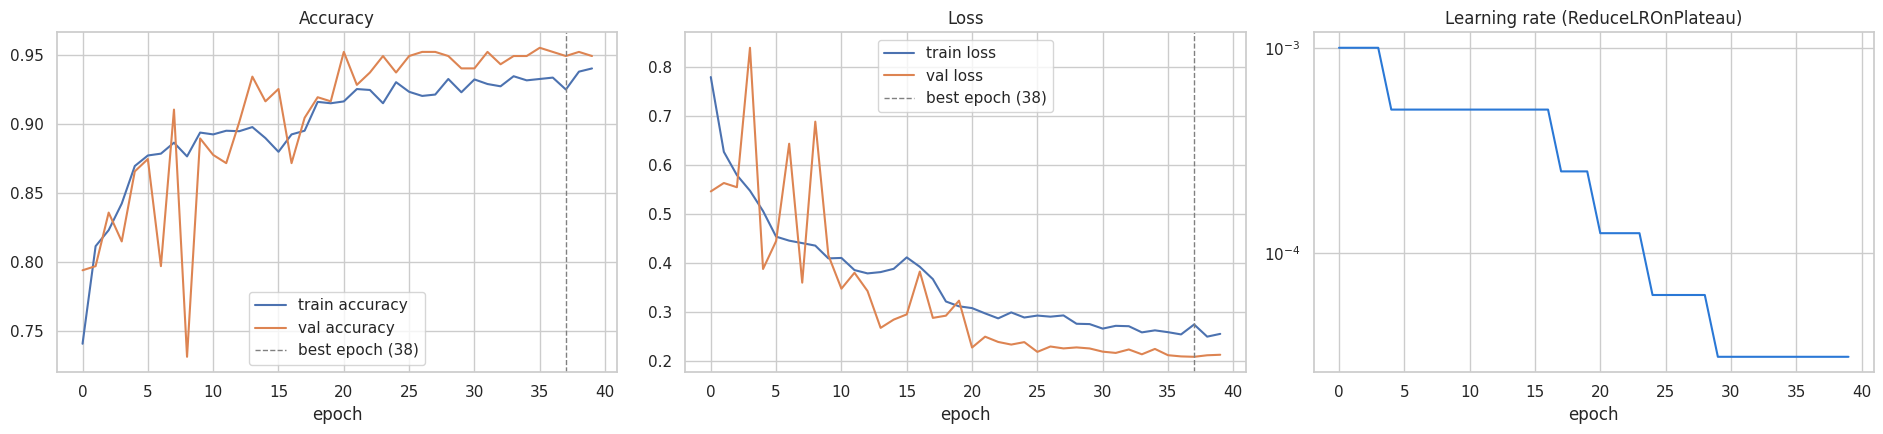

In [ ]:
EPOCHS = 40          # upper limit; EarlyStopping usually stops earlier

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(str(MODEL_PATH), monitor='val_loss', save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
]

t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weight, callbacks=callbacks)
hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
train_minutes = (time.time() - t0) / 60
best_epoch = int(np.argmin(hist['val_loss'])) + 1
print(f'Training finished in {train_minutes:.1f} min ({len(hist["loss"])} epochs, best epoch {best_epoch}). '
      f'Best model saved to {MODEL_PATH}')

lr_key = 'learning_rate' if 'learning_rate' in hist else ('lr' if 'lr' in hist else None)
fig, axes = plt.subplots(1, 3 if lr_key else 2, figsize=(19 if lr_key else 14, 4.5))
for ax, metric in zip(axes, ['accuracy', 'loss']):
    ax.plot(hist[metric], label=f'train {metric}'); ax.plot(hist[f'val_{metric}'], label=f'val {metric}')
    ax.axvline(best_epoch - 1, color='grey', ls='--', lw=1, label=f'best epoch ({best_epoch})')
    ax.set_xlabel('epoch'); ax.set_title(metric.capitalize()); ax.legend()
if lr_key:
    axes[2].plot(hist[lr_key], color='#2a78d6'); axes[2].set_yscale('log')
    axes[2].set_title('Learning rate (ReduceLROnPlateau)'); axes[2].set_xlabel('epoch')
plt.tight_layout(); plt.savefig(MODELS_DIR / 'training_curves.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Model testing & evaluation

The **best checkpoint is re-loaded from Drive** (the same file the API will serve) and evaluated on the untouched
`test/` split:

* **Accuracy**
* **Precision, Recall, F1**, both **macro** (every class equal, the honest number with imbalance) and **weighted**
* **Per-class classification report**
* **Confusion matrix** → which diseases get mixed up
* **One-vs-Rest ROC curves + AUC** → how well the predicted probabilities separate each class from the rest

In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

best_model = tf.keras.models.load_model(MODEL_PATH)
y_true = np.array(test_labels)
y_prob = best_model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)

acc = accuracy_score(y_true, y_pred)
p_mac, r_mac, f_mac, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
y_bin = label_binarize(y_true, classes=range(len(CLASS_NAMES)))
roc_auc_macro = roc_auc_score(y_bin, y_prob, average='macro', multi_class='ovr')
test_loss = float(tf.keras.losses.sparse_categorical_crossentropy(y_true, y_prob).numpy().mean())

metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC (OvR)', 'Log loss'],
    'Macro': [acc, p_mac, r_mac, f_mac, roc_auc_macro, test_loss],
    'Weighted': [acc, p_w, r_w, f_w, roc_auc_score(y_bin, y_prob, average='weighted', multi_class='ovr'), test_loss],
}).set_index('Metric').round(4)
display(metrics_df)

report = classification_report(y_true, y_pred, labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES, digits=4, output_dict=True, zero_division=0)
print(classification_report(y_true, y_pred, labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES, digits=4, zero_division=0))

,Macro,Weighted
Metric,,
Accuracy,0.9449,0.9449
Precision,0.9261,0.9478
Recall,0.9382,0.9449
F1-score,0.9311,0.9456
ROC-AUC (OvR),0.9927,0.9944
Log loss,0.1470,0.1470


                precision    recall  f1-score   support

        Blight     0.9390    0.8929    0.9153       224
   Common_Rust     0.9840    0.9609    0.9723       256
Gray_Leaf_Spot     0.7903    0.8991    0.8412       109
       Healthy     0.9913    1.0000    0.9956       227

      accuracy                         0.9449       816
     macro avg     0.9261    0.9382    0.9311       816
  weighted avg     0.9478    0.9449    0.9456       816



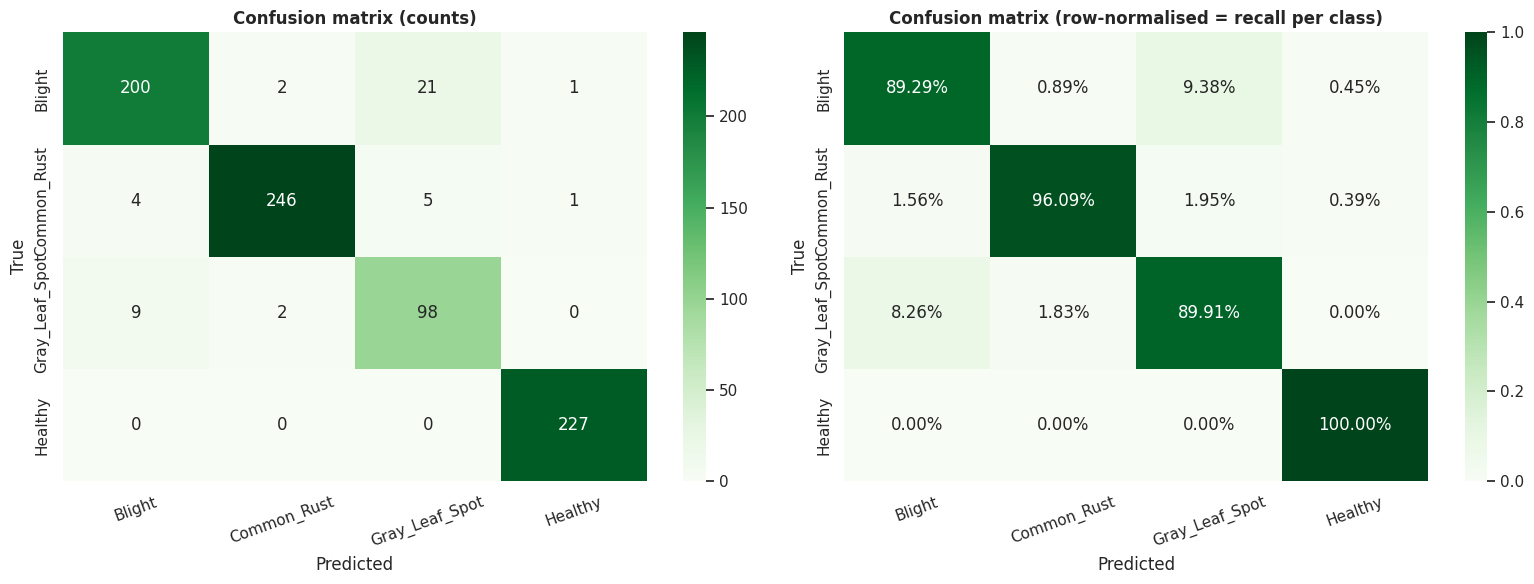

Most common confusion: 21 × true Blight predicted as Gray_Leaf_Spot
Most common confusion: 9 × true Gray_Leaf_Spot predicted as Blight
Most common confusion: 5 × true Common_Rust predicted as Gray_Leaf_Spot


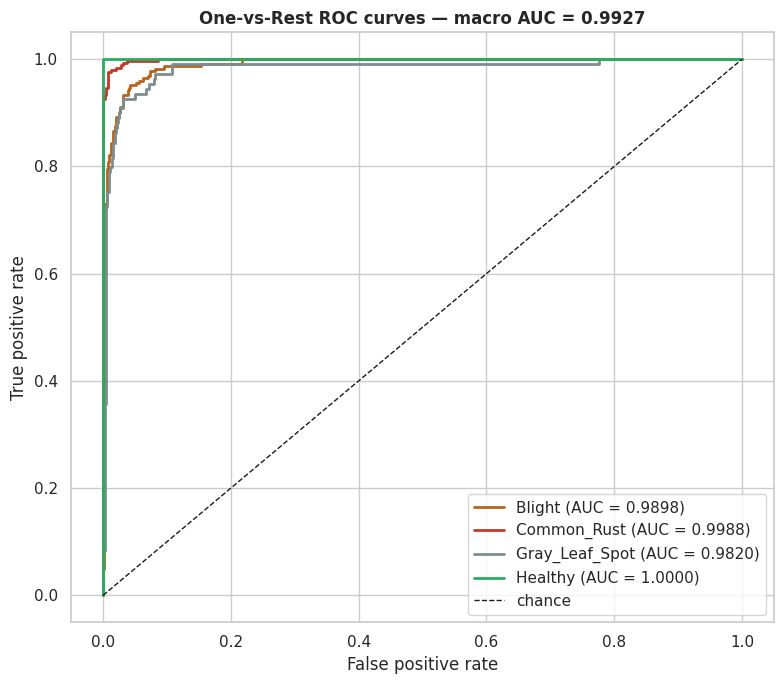

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Confusion matrix (counts)', weight='bold')
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title('Confusion matrix (row-normalised = recall per class)', weight='bold')
for ax in axes:
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(MODELS_DIR / 'confusion_matrix.png', dpi=200, bbox_inches='tight'); plt.show()

off_diag = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(len(CLASS_NAMES)) for j in range(len(CLASS_NAMES)) if i != j and cm[i, j] > 0]
for t, p, n in sorted(off_diag, key=lambda x: -x[2])[:3]:
    print(f'Most common confusion: {n} × true {t} predicted as {p}')

# One-vs-Rest ROC curves
plt.figure(figsize=(8, 7))
per_class_auc = {}
for i, cls in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    per_class_auc[cls] = float(auc(fpr, tpr))
    plt.plot(fpr, tpr, lw=2, color=palette[cls], label=f'{cls} (AUC = {per_class_auc[cls]:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='chance')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title(f'One-vs-Rest ROC curves — macro AUC = {roc_auc_macro:.4f}', weight='bold')
plt.legend(loc='lower right'); plt.tight_layout()
plt.savefig(MODELS_DIR / 'roc_curves.png', dpi=200, bbox_inches='tight'); plt.show()

In [ ]:
model_metadata = {
    'class_names': CLASS_NAMES,
    'model_version': 'v1.0',
    'last_trained': datetime.now(timezone.utc).isoformat(),
    'accuracy': round(float(acc), 4),
    'precision': round(float(p_mac), 4),
    'recall': round(float(r_mac), 4),
    'f1_score': round(float(f_mac), 4),
    'roc_auc': round(float(roc_auc_macro), 4),
    'precision_weighted': round(float(p_w), 4),
    'recall_weighted': round(float(r_w), 4),
    'f1_weighted': round(float(f_w), 4),
    'test_loss': round(test_loss, 4),
    'per_class_auc': {k: round(v, 4) for k, v in per_class_auc.items()},
    'per_class_report': {c: {k: round(float(v), 4) for k, v in report[c].items()} for c in CLASS_NAMES},
    'confusion_matrix': cm.tolist(),
    'train_samples': len(all_train_paths),
    'test_samples': len(test_paths),
    'validation_samples': len(val_paths),
    'architecture': 'Custom CNN trained from scratch: stem + 4 conv blocks (32-64-128-256) + GAP + Dense(128) + Dense(4, softmax)',
    'trained_from_scratch': True,
    'parameters': int(model.count_params()),
    'best_epoch': best_epoch,
    'input_size': [IMG_SIZE, IMG_SIZE, 3],
    'preprocessing': 'RGB -> resize 224x224 bilinear -> x/127.5 - 1',
    'epochs_trained': len(hist['loss']),
    'training_minutes': round(train_minutes, 2),
    'tf_version': tf.__version__,
    'keras_version': keras.__version__,
    'retrain_history': [],
}
with open(MODELS_DIR / 'model_metadata.json', 'w') as f:
    json.dump(model_metadata, f, indent=2)
print(json.dumps({k: v for k, v in model_metadata.items() if k not in ('per_class_report', 'confusion_matrix')}, indent=2))

{
  "class_names": [
    "Blight",
    "Common_Rust",
    "Gray_Leaf_Spot",
    "Healthy"
  ],
  "model_version": "v1.0",
  "last_trained": "2026-11-23T20:50:49.572340+00:00",
  "accuracy": 0.9449,
  "precision": 0.9261,
  "recall": 0.9382,
  "f1_score": 0.9311,
  "roc_auc": 0.9927,
  "precision_weighted": 0.9478,
  "recall_weighted": 0.9449,
  "f1_weighted": 0.9456,
  "test_loss": 0.147,
  "per_class_auc": {
    "Blight": 0.9898,
    "Common_Rust": 0.9988,
    "Gray_Leaf_Spot": 0.982,
    "Healthy": 1.0
  },
  "train_samples": 3348,
  "test_samples": 816,
  "validation_samples": 335,
  "architecture": "Custom CNN trained from scratch: stem + 4 conv blocks (32-64-128-256) + GAP + Dense(128) + Dense(4, softmax)",
  "trained_from_scratch": true,
  "parameters": 1217892,
  "best_epoch": 38,
  "input_size": [
    224,
    224,
    3
  ],
  "preprocessing": "RGB -> resize 224x224 bilinear -> x/127.5 - 1",
  "epochs_trained": 40,
  "training_minutes": 10.04,
  "tf_version": "2.21.0",
  "kera

## 6. Prediction — single-image function

`predict_single_image` mirrors `src/prediction.py`: read bytes → shared preprocessing → softmax → class, confidence and
all class probabilities. Predictions under **0.65 confidence** are flagged as *low confidence*; the API counts these
and uses them as one of the retraining triggers.

Below it's demonstrated on one random **test** image per class and on the **unseen `demo_upload_batch`** images that you
will later upload through the UI to trigger retraining.

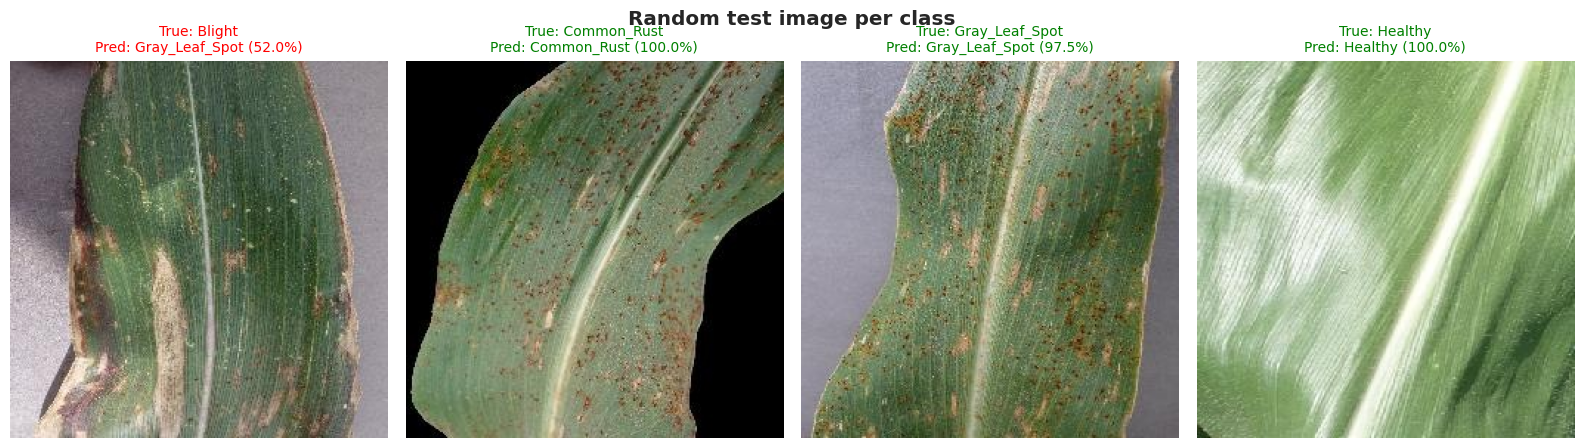

{
  "predicted_class": "Gray_Leaf_Spot",
  "confidence": 0.5201,
  "probabilities": {
    "Blight": 0.4798,
    "Common_Rust": 0.0001,
    "Gray_Leaf_Spot": 0.5201,
    "Healthy": 0.0
  },
  "low_confidence": true
}

Unseen demo_upload_batch: 20/20 correct


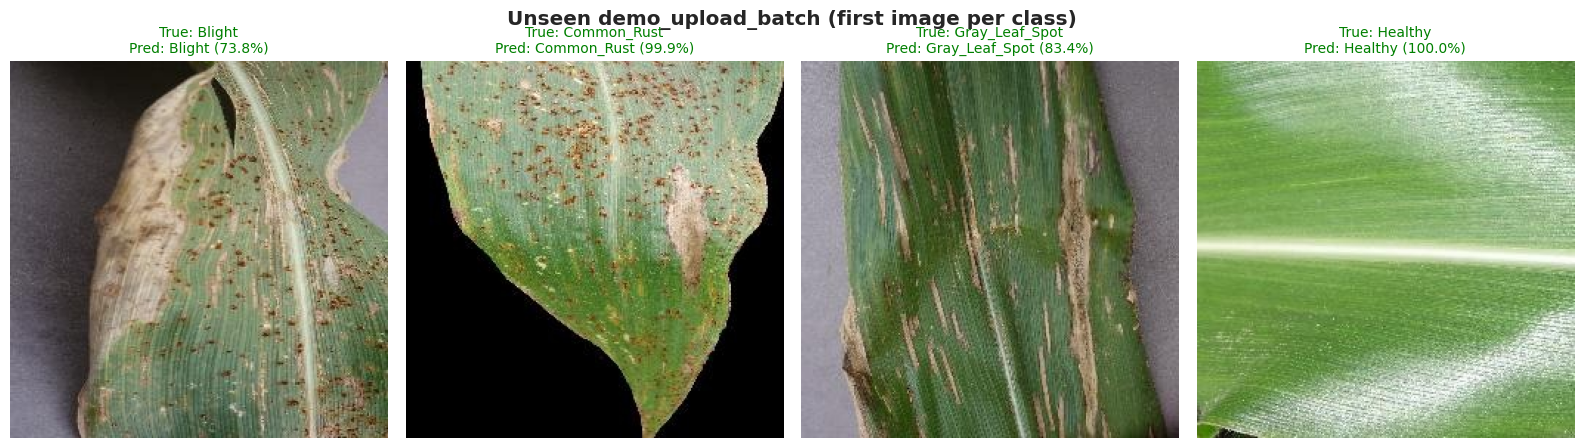

In [ ]:
LOW_CONFIDENCE_THRESHOLD = 0.65

def preprocess_image_bytes(image_bytes):
    img = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    return preprocess_pixels(img)[tf.newaxis, ...]

def predict_single_image(image_path, model=best_model):
    with open(image_path, 'rb') as f:
        x = preprocess_image_bytes(f.read())
    probs = model(x, training=False).numpy()[0]
    idx = int(np.argmax(probs))
    return {'predicted_class': CLASS_NAMES[idx], 'confidence': round(float(probs[idx]), 4),
            'probabilities': {c: round(float(p), 4) for c, p in zip(CLASS_NAMES, probs)},
            'low_confidence': bool(probs[idx] < LOW_CONFIDENCE_THRESHOLD)}

def show_predictions(paths, true_labels, title):
    fig, axes = plt.subplots(1, len(paths), figsize=(4 * len(paths), 4.6))
    for ax, p, t in zip(np.atleast_1d(axes), paths, true_labels):
        res = predict_single_image(p)
        ok = res['predicted_class'] == t
        ax.imshow(Image.open(p)); ax.axis('off')
        ax.set_title(f"True: {t}\nPred: {res['predicted_class']} ({res['confidence']:.1%})",
                     color='green' if ok else 'red', fontsize=10)
    plt.suptitle(title, weight='bold'); plt.tight_layout(); plt.show()

rng = random.Random(SEED)
pick_classes = [c for i, c in enumerate(CLASS_NAMES) if i in set(test_labels)]
picks = [rng.choice([p for p, y in zip(test_paths, test_labels) if y == CLASS_NAMES.index(c)]) for c in pick_classes]
show_predictions(picks, pick_classes, 'Random test image per class')
print(json.dumps(predict_single_image(picks[0]), indent=2))

demo_files = [(str(p), cls) for cls in CLASS_NAMES for p in sorted((DEMO_DIR / cls).glob('*.jpg'))]
demo_correct = sum(predict_single_image(p)['predicted_class'] == c for p, c in demo_files)
print(f'\nUnseen demo_upload_batch: {demo_correct}/{len(demo_files)} correct')
show_predictions([p for p, _ in demo_files[::5]], [c for _, c in demo_files[::5]], 'Unseen demo_upload_batch (first image per class)')

## 7. Package the artifacts for the API

The last cell zips what the backend needs into Drive so you can download it in one go:

* `corn_api_artifacts.zip` → `models/` (`corn_disease_model.keras`, `model_metadata.json`, `eda_stats.json`, plots)
  and `data/train`, `data/test` (needed on the server for **retraining** and evaluation).
* `demo_upload_batch.zip` → the 20 unseen images, one folder per class. Upload this zip in the UI's bulk upload to
  trigger retraining.

Unzip `corn_api_artifacts.zip` in the root of the GitHub repo so the paths match `src/__init__.py`.

In [ ]:
def zip_folders(zip_path, folders, root):
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
        for folder in folders:
            for f in Path(folder).rglob('*'):
                if f.is_file():
                    zf.write(f, f.relative_to(root))

artifacts_zip = BASE_DIR / 'corn_api_artifacts.zip'
zip_folders(artifacts_zip, [MODELS_DIR, TRAIN_DIR, TEST_DIR], BASE_DIR)
zip_folders(BASE_DIR / 'demo_upload_batch.zip', [DEMO_DIR], DEMO_DIR)
for z in [artifacts_zip, BASE_DIR / 'demo_upload_batch.zip']:
    print(f'{z.name}: {z.stat().st_size / 1e6:.1f} MB  ->  {z}')
print('\nModel files:')
for f in sorted(MODELS_DIR.glob('*')):
    if f.is_file():
        print(f'  {f.name:32s} {f.stat().st_size / 1e6:7.2f} MB')

if IN_COLAB:
    print('\nDownload from Drive (MyDrive/corn_disease_mlops) or run: from google.colab import files; files.download(str(artifacts_zip))')

corn_api_artifacts.zip: 221.2 MB  ->  /content/drive/MyDrive/corn_disease_mlops/corn_api_artifacts.zip
demo_upload_batch.zip: 0.5 MB  ->  /content/drive/MyDrive/corn_disease_mlops/demo_upload_batch.zip

Model files:
  confusion_matrix.png                0.18 MB
  corn_disease_model.keras           14.77 MB
  eda_features.png                    0.26 MB
  eda_stats.json                      0.01 MB
  model_metadata.json                 0.00 MB
  roc_curves.png                      0.13 MB
  sample_images.png                   3.08 MB
  training_curves.png                 0.17 MB

Download from Drive (MyDrive/corn_disease_mlops) or run: from google.colab import files; files.download(str(artifacts_zip))
